# CSC_51054_EP - Deep Learning
## Lab 6: Deep Visual Representation Learning

### Section 1. Introduction
#### *What is Visual Representation?*

In computer vision, a **visual representation** refers to the transformation of raw image pixels into a structured and informative format that a machine learning model can use to understand and reason about visual content.

Rather than operating directly on pixel intensities, modern vision systems extract **representations**, which are typically compact and often high-dimensional vectors, that encode semantic, structural, or spatial information about the input visual data (e.g., images or videos).

#### *Why is Visual Representation Important?*

- ✅ **Foundation of most CV tasks**: Classification, detection, segmentation, retrieval, and even image generation all rely on strong underlying representations.
- 🧠 **Bridge between perception and decision**: A good visual representation helps models understand "what is in the image" and "how it relates to other images."
- 🚀 **Transferability**: Powerful representations trained on large datasets (like ImageNet) can be reused for many downstream tasks with minimal fine-tuning.
- 🏗️ **Modularity and Generalization**: Representations allow decoupling feature extraction from task-specific heads.

### Section 2: Lab Overview and Setup

In this tutorial, we will walk through several approaches to visual representation learning, ranging from traditional hand-crafted features to modern and the state-of-the-art deep learning–based models.

#### 🧭 Lab Structure

1. **Classic Feature Engineering**: Use HOG (Histogram of Oriented Gradients) [[CVPR'05]](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf) to extract basic image representations. (💡Fun fact: HOG is from Inria)
2. **Training a CNN**: Build and train a simple convolutional neural network from scratch on [CIFAR-100](https://www.cs.toronto.edu/~kriz/cifar.html).
3. **Advanced Representation with Transformers**: Use a pretrained DINO-ViT [[ICCV'21]](https://arxiv.org/abs/2104.14294) as a feature extractor.
4. **Feature Visualizations**: Use t-SNE to visualize and compare the representations learned from each method.
5. **Discussion**: Open challenges in deep visual representation learning (if we have time).

#### 🖼️ Dataset: [CIFAR-100](https://www.cs.toronto.edu/~kriz/cifar.html)
- 100 object categories
- 32x32 color images
- 600 images per class (500 train / 100 test)
- Diverse classes ranging from animals to vehicles

#### 🎯 Downstream Task: Image Classification
We will use extracted features for:
- Linear classification (Logistic Regression or a linear layer)
- t-SNE for visual inspection of representation quality

#### 🤔 Discussion: Unsolved Problems in Representation Learning

While deep visual representations have significantly advanced the field of computer vision, several challenges remain open:

- **Long-tail distributions**: Most datasets (including CIFAR-100) are balanced, but real-world data is often highly skewed, with many rare classes poorly represented.
- **Robustness to distribution shift**: Features that perform well on the training distribution may fail in new domains.
- **Interpretability**: Understanding what aspects of the image are encoded in a representation remains difficult.
- **Bias and fairness**: Representations can carry or amplify dataset biases, affecting downstream decisions.

These challenges make visual representation learning a continually evolving and active research area.


In [4]:
!pip install timm -q
!pip install scikit-image -q

# Standard libraries
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import timm

# Image processing (for classic features)
from skimage.feature import hog
from skimage.color import rgb2gray

# Set the device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(device)

mps


In [5]:
# Fetch dataset CIFAR100
from torchvision.datasets import CIFAR100

# Base transform: convert to tensor and normalize to [0, 1]
base_transform = transforms.Compose([
    transforms.ToTensor(),  # Converts to [0, 1]
])

# For HOG and shallow CNN, we use the original 32x32 images
train_dataset = CIFAR100(root='./data', train=True, download=True, transform=base_transform)
test_dataset  = CIFAR100(root='./data', train=False, download=True, transform=base_transform)

# Dataloaders
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

# Also grab class names
class_names = train_dataset.classes
print(f"Number of classes: {len(class_names)}")

Number of classes: 100


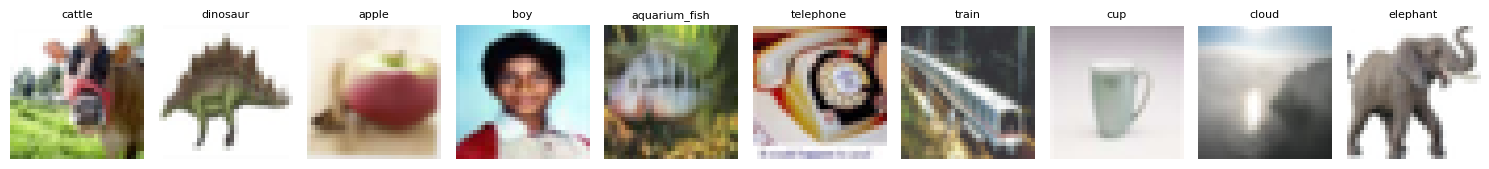

In [6]:
# Show a few examples of CIFAR-100
def show_cifar_samples(dataset, class_names, num_images=10):
    """Display a few sample images from the CIFAR-100 dataset."""
    plt.figure(figsize=(15, 2))
    for i in range(num_images):
        img, label = dataset[i]
        img = img.permute(1, 2, 0).numpy()  # CHW to HWC for plotting
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.title(class_names[label], fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Show 10 training samples
show_cifar_samples(train_dataset, class_names, num_images=10)


### Section 3: Classic Image Descriptors as Visual Representations (e.g. HOG)

#### What is HOG?

**HOG (Histogram of Oriented Gradients)** is a classic feature descriptor used in traditional computer vision before the rise of deep learning. It was introduced by Dalal and Triggs in their 2005 [CVPR paper](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf) for the task of pedestrian detection.

The core idea behind HOG is simple but powerful:
- It captures **local edge directions** by computing gradient orientations in small spatial regions (called cells).
- These orientations are aggregated into histograms, which encode texture and shape information.
- The result is a **fixed-length feature vector** that describes the structure of the image without using pixel intensities directly.

Although HOG features are not learned from data (unlike CNN or ViT), they are still useful for capturing **low-level visual patterns** like edges, corners, and contours.


<span style="color:blue">**Tasks:**</span> Fill in the indicated blanks in the following code cells for extracting HOG features from CIFAR-100 and test the classification performance using Logistic Regression, and finally plot the t-SNE for viusalization and analysis. 
 - Code for fitting and evaluating the logistic regression model on HOG features.
 - Call the ''plot_tsne_with_legend'' function to visualize and analyze the HOG visual representations.

In [7]:
def extract_hog_features(dataset, pixels_per_cell=(4, 4), cells_per_block=(2, 2), visualize=False):
    """
    Extract HOG features from CIFAR-100 images (converting them to grayscale first).
    Returns: X (features), y (labels)
    """
    X, y = [], []

    for img, label in tqdm(dataset, desc="Extracting HOG features"):
        img_gray = rgb2gray(img.permute(1, 2, 0).numpy())  # Convert tensor to HWC then to grayscale
        hog_vec = hog(img_gray,
                      pixels_per_cell=pixels_per_cell,
                      cells_per_block=cells_per_block,
                      visualize=visualize,
                      feature_vector=True)
        X.append(hog_vec)
        y.append(label)

    return np.array(X), np.array(y)

# Extract features from train and test sets (this may take ~1-2 mins)
X_train_hog, y_train = extract_hog_features(train_dataset)
X_test_hog, y_test = extract_hog_features(test_dataset)
print("Check feature dims:",np.shape(X_train_hog), np.shape(X_test_hog))
print("Check labels:", np.shape(y_train))

Extracting HOG features: 100%|██████████████████████████████████████████████████| 10000/10000 [00:03<00:00, 2863.17it/s]

Check feature dims: (50000, 1764) (10000, 1764)
Check labels: (50000,)


In [8]:
# Train a Logistic Regression model on HOG features
print("Training Logistic Regression on HOG features...")
clf_lr = LogisticRegression(max_iter=300, solver='lbfgs', verbose=1)

### TO BE FILLED ### this could take a few minutes
clf_lr.fit(X_train_hog, y_train)

# Evaluate on test set

### TO BE FILLED ###
y_pred_lr = clf_lr.predict(X_test_hog)
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy on CIFAR-100 (HOG): {acc_lr:.4f}")


Training Logistic Regression on HOG features...
RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =       176500     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  4.60517D+00    |proj g|=  2.17100D-03


 This problem is unconstrained.



At iterate   50    f=  2.72019D+00    |proj g|=  1.13066D-02

At iterate  100    f=  2.54882D+00    |proj g|=  1.61737D-03

At iterate  150    f=  2.49593D+00    |proj g|=  2.51995D-03

At iterate  200    f=  2.46411D+00    |proj g|=  6.10335D-04

At iterate  250    f=  2.45787D+00    |proj g|=  1.63175D-04


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:  3.7min finished



           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
*****    271    286      1     0     0   9.354D-05   2.457D+00
  F =   2.4569360142187251     

CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL            
Logistic Regression Accuracy on CIFAR-100 (HOG): 0.2038


In [9]:
def plot_tsne_with_legend(X, y, class_names, num_classes=10, title="t-SNE of HOG features"):
    """
    Run t-SNE on a subset of features and plot with class name legend.
    """
    # Subsample to make t-SNE faster and clearer
    num_per_class = 50
    selected_idx = []

    for cls in range(num_classes):
        idx = np.where(y == cls)[0][:num_per_class]
        selected_idx.extend(idx)

    X_sub = X[selected_idx]
    y_sub = y[selected_idx]

    print("Running t-SNE...")
    tsne = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto")
    X_embedded = tsne.fit_transform(X_sub)

    # Plot
    plt.figure(figsize=(10, 6))
    for cls in range(num_classes):
        idx = y_sub == cls
        plt.scatter(X_embedded[idx, 0],
                    X_embedded[idx, 1],
                    s=12,
                    label=class_names[cls])
    
    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.legend(markerscale=1.5, fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    plt.show()


Running t-SNE...


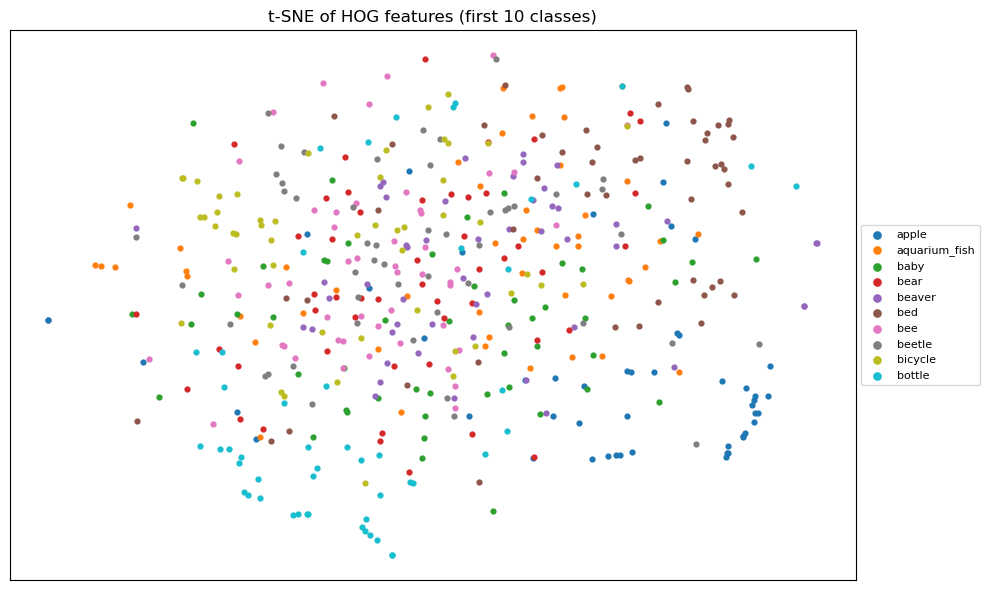

In [10]:
### TO BE FILLED: visualize the plot ###
plot_tsne_with_legend(X_test_hog, y_test, class_names, num_classes=10, title="t-SNE of HOG features (first 10 classes)")


<span style="color:orange">**Questions:**</span> 
 - How to understand the log from the logistic regression model?
 - How to understand the t-SNE visulizations?

<span style="color:green">**Answers:**</span>
 - **A1:** In the log of logistic regression,
   - `f`: This is the **current loss** value, and it should **decrease over time** as the model learns.
   - `|proj g|`: This is the **norm of the projected gradient**, indicating how close we are to a global minimum. The smaller it is, the closer we are to convergence.
   - The optimizer (e.g., L-BFGS) runs iterations to minimize the loss. Once `|proj g|` is small enough or max iterations are reached, training stops.
     
   If the log shows that `f` is not decreasing or `|proj g|` remains large, it may suggest:
   - The model is underfitting or overfitting
   - The learning rate is too low/high
   - The features are not separable (e.g., HOG may not linearly separate all classes well)

 - **A2:** t-SNE is a dimensionality reduction method that projects **high-dimensional features** into a 2D space to **visualize the structure of the feature space**.

   In the scatter plot:

   - Each dot represents one image (its extracted feature)
   - Dots are colored by class label
   - If the representation is **good**, samples from the same class will **cluster together**, while different classes will be well separated
   - If the representation is **not discriminative**, the clusters will overlap or appear diffuse

### Section 4: CNN for visual representation learning and downstream applications

We have previously introduced Convolutional Neural Networks (CNNs) in the lectures and experimented with them in earlier lab sessions. 
In this section, we will build a simple CNN from scratch and apply it to visual representation learning and classification on CIFAR-100.

<span style="color:blue">**Tasks:**</span> Train a CNN to learn the visual representations for the multi-class classification task.
 - The missing architecture components in the `CNN` class
 - Definition of training setup, e.g., loss function and optimizer
 - Training function of the ShallowCNN in `train_one_epoch`
 - Actual training process
 - Call the feature extraction function and create the t-SNE plot.

In [11]:
class CNN(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        ### To Be Filled
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x, return_features=False):
        x = self.pool(F.relu(self.conv1(x)))  # [B, 32, 16, 16]
        x = self.pool(F.relu(self.conv2(x)))  # [B, 64, 8, 8]
        x = self.pool(F.relu(self.conv3(x)))  # [B, 128, 4, 4]
        x = x.view(x.size(0), -1)             # Flatten
        features = F.relu(self.fc1(x))        # 256-dim feature
        logits = self.fc2(features)
        return (logits, features) if return_features else logits


In [12]:
# Instantiate model, loss function, and optimizer

### TO BE FILLED ### model definition, loss function, and optimizer 
model = CNN(num_classes=100).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(dataloader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)

        ### TO BE FILLED ###
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    avg_loss = running_loss / total
    acc = correct / total
    return avg_loss, acc


def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    acc = correct / total
    return avg_loss, acc

Epoch 1/10


Train Acc: 0.1170 | Test Acc: 0.1991
Epoch 2/10


Train Acc: 0.2371 | Test Acc: 0.2735
Epoch 3/10


Train Acc: 0.3026 | Test Acc: 0.3136
Epoch 4/10


Train Acc: 0.3483 | Test Acc: 0.3399
Epoch 5/10


...

Train Acc: 0.4229 | Test Acc: 0.3785
Epoch 7/10


Train Acc: 0.4564 | Test Acc: 0.3952
Epoch 8/10


Train Acc: 0.4807 | Test Acc: 0.3901
Epoch 9/10


Train Acc: 0.5113 | Test Acc: 0.4062
Epoch 10/10


Train Acc: 0.5424 | Test Acc: 0.4043


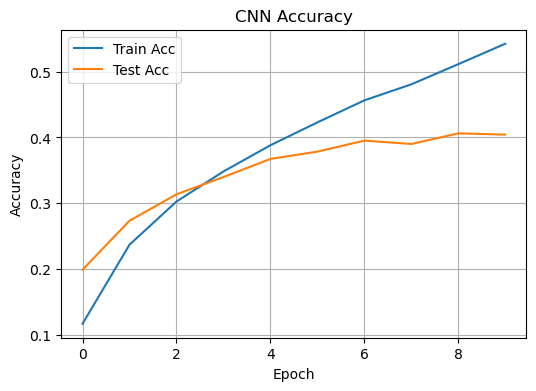

In [13]:
num_epochs = 10
train_losses, train_accs = [], []
test_losses, test_accs = [], []

for epoch in range(num_epochs):
    print(f"Epoch {epoch+1}/{num_epochs}")

    ### TO BE FILLED ###
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(f"Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

# Plot accuracy curve
plt.figure(figsize=(6, 4))
plt.plot(train_accs, label='Train Acc')
plt.plot(test_accs, label='Test Acc')
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [14]:
#### Function to extract features for t-SNE visulizations and analysis
def extract_cnn_features(model, dataloader, device, num_classes=10, samples_per_class=50):
    """
    Extract 256-dim features from CNN (fc1 layer).
    """
    model.eval()
    features = []
    labels = []
    class_counts = {cls: 0 for cls in range(num_classes)}

    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            outputs, feats = model(images, return_features=True)

            for i in range(len(images)):
                label = targets[i].item()
                if label < num_classes and class_counts[label] < samples_per_class:
                    features.append(feats[i].cpu().numpy())
                    labels.append(label)
                    class_counts[label] += 1

            # stop early if all classes filled
            if all(count >= samples_per_class for count in class_counts.values()):
                break

    return np.array(features), np.array(labels)


Running t-SNE...


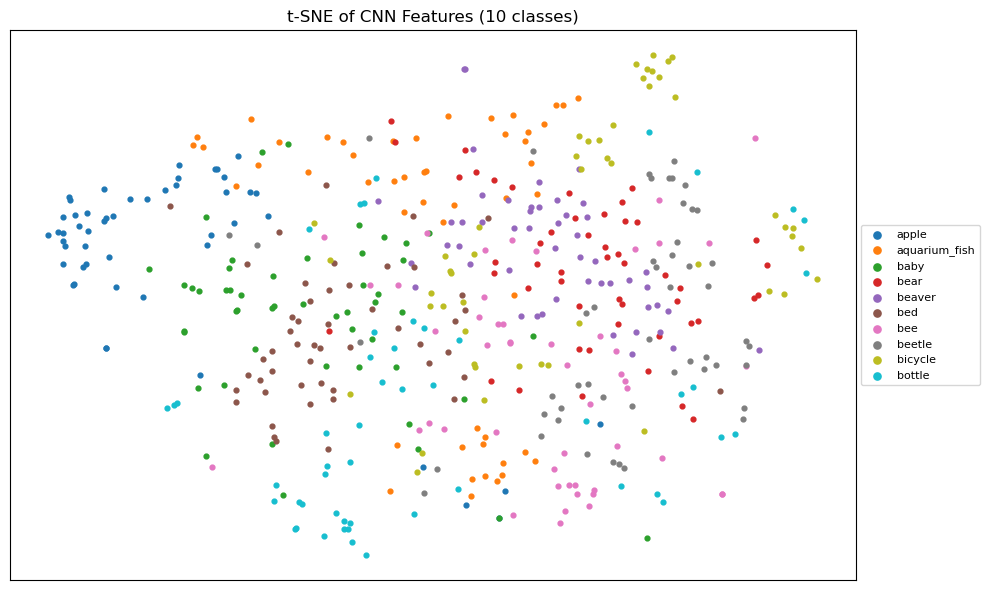

In [15]:
# Extract features (e.g. for first 10 classes)
### TO BE FILLED ### call the function
X_cnn, y_cnn = extract_cnn_features(model, test_loader, device, num_classes=10, samples_per_class=50)

### TO BE FILLED ### plot the CNN features
# Plot using t-SNE with class legends
plot_tsne_with_legend(X_cnn, y_cnn, class_names, num_classes=10, title="t-SNE of CNN Features (10 classes)")

<span style="color:orange">**Questions:**</span> 
 - How is the classification performance compared to our previous case from **Section 3**? And why do you think the change happens?
 - What can we know about the T-SNE in this case?
   
<span style="color:green">**Answers:**</span>
- **A1:** Compared to Section 3 (HOG + Logistic Regression), the CNN achieves **higher classification accuracy** (from ~20% to ~40%) on the CIFAR-100 dataset.
   **Why the improvement?**
   - HOG is a hand-crafted feature descriptor, which may not be optimal for complex or abstract visual patterns.
   - CNN learns task-specific features directly from data via backpropagation, making it more adaptive and expressive.
   - Even with a shallow CNN and only 10 epochs, we already see clear improvements due to its capacity to learn hierarchical visual patterns (edges → textures → objects).

- **A2:** The t-SNE plot of CNN features shows **better clustering** than the HOG-based version:

   - Classes like `apple`, `bottle`, and `bicycle` are **more compact** and **well-separated**.
   - However, there is still some overlap between similar or visually confusing categories (e.g., `bear` and `beaver`).

   This indicates that CNN features:

   - Learn **semantically meaningful** representations (e.g., color, shape)
   - Are **not yet perfectly separable**, especially for similar-looking classes, due to limited model capacity or short training time

As we use more complex models (e.g., DINO-ViT), we expect even **clearer clusters** in t-SNE space.

### Section 5: Self-supervised deep visual representations with DINO-VIT

In this final section, we explore **self-supervised learning** with Vision Transformers (ViTs), focusing on **DINO** (Self-Distillation with No Labels) – a state-of-the-art approach for learning visual representations **without any human-labeled data**.

While CNNs extract local patterns using convolutional filters, Vision Transformers (ViTs) process images as sequences of patches using **self-attention** mechanisms, enabling them to capture **global semantic structure** more effectively.

**DINO (Caron et al., 2021)** trains a ViT using self-distillation: a student network learns from a moving-average teacher, both receiving differently augmented views of the same image, all **without access to class labels**. Surprisingly, the representations learned this way can be used directly for tasks like classification, retrieval, or clustering.

📎 **References**:
- Caron et al., [Emerging Properties in Self-Supervised Vision Transformers](https://arxiv.org/abs/2104.14294), *ICCV 2021*.
- Dosovitskiy et al., [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929), *ICLR 2021* (ViT paper).

💡 **Fun fact**: With no labels and just data augmentations, DINO-ViT learns to separate object categories naturally in feature space. From my personal perspective (YZ), this a big step toward **human-like learning** from raw perception.

In this section, we will:
- Extract visual features from a pretrained DINO-ViT model.
- Use these features for linear classification (logistic regression).
- Visualize the representation structure using t-SNE.

Let's see how far we can go without labels!

---
<span style="color:blue">**Tasks:**</span> Extract visual representations from a pre-trained DINO-VIT.
 - Using the pre-defined extract_dino_features function to extract features for t-SNE
 - If time permits, using the extracted features to perform the classification, and compare the performance with previous two sections


In [16]:
# Load pretrained DINO ViT model from timm
model_dino = timm.create_model('vit_small_patch16_224_dino', pretrained=True).to(device)
model_dino.eval()

/Users/yezhu/miniconda3/envs/jupyterlab/lib/python3.10/site-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name vit_small_patch16_224_dino to current vit_small_patch16_224.dino.
  model = create_fn(


VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

In [17]:
# DINO ViT expects 224x224 images and normalized inputs
vit_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5]),  # approximate normalization
])

### For cleaning coding reason, we will load the dataset again
# Load CIFAR-100 with ViT-compatible transform
cifar_train_vit = CIFAR100(root='./data', train=True, transform=vit_transform)
cifar_test_vit = CIFAR100(root='./data', train=False, transform=vit_transform)

# Create dataloaders
cifar_train_vit_loader = DataLoader(cifar_train_vit, batch_size=64, shuffle=False)
cifar_test_vit_loader = DataLoader(cifar_test_vit, batch_size=64, shuffle=False)


In [18]:
def extract_dino_features(model, dataloader, num_classes=10, samples_per_class=50, device=device):
    model.to(device)
    model.eval()

    features = []
    labels = []

    with torch.no_grad():
        for images, targets in tqdm(dataloader, desc="Extracting DINO features"):
            images = images.to(device)

            ### Important: We only need the CLS token for our t-SNE visualization and classification
            tokens = model.forward_features(images)  # [B, 197, 384]
            cls = tokens[:, 0, :]  # [B, 384]
            
            features.append(cls.cpu().numpy())
            labels.append(targets.numpy())

    features = np.concatenate(features, axis=0)  # [N, 384]
    labels = np.concatenate(labels, axis=0)      # [N]
    return features, labels


Extracting DINO features: 100%|███████████████████████████████████████████████████████| 157/157 [00:48<00:00,  3.22it/s]


check DINO features: (10000, 384)
Running t-SNE...


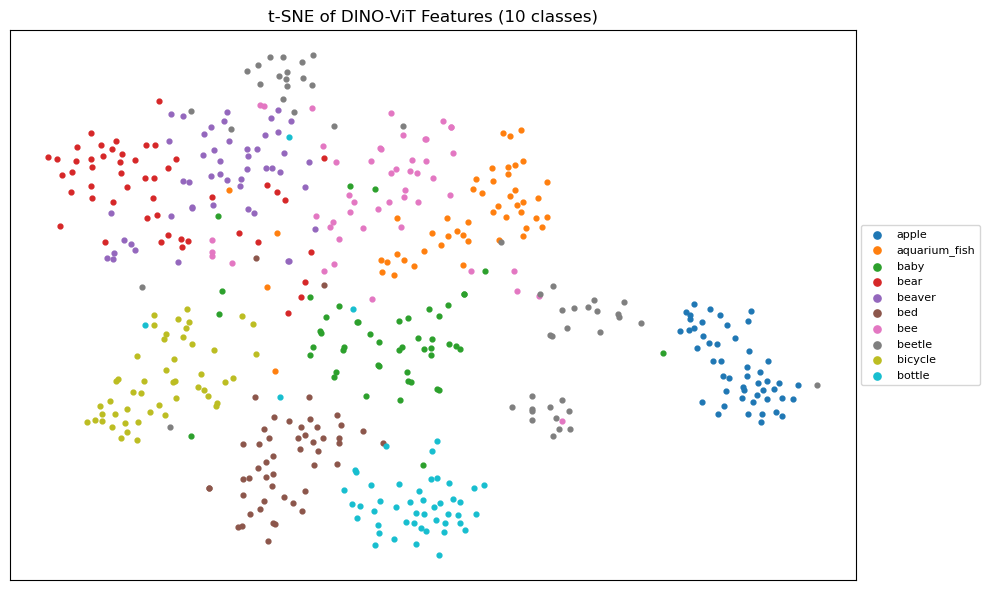

In [19]:
### TO BE FILLED ###
## using the test set from CIFAR for feature extraction for t-SNE visualization, we only need 10 classes and 50 samples per class
X_dino, y_dino = extract_dino_features(model_dino, cifar_test_vit_loader, num_classes=10, samples_per_class=50, device=device)
print("check DINO features:", np.shape(X_dino))

plot_tsne_with_legend(X_dino, y_dino, class_names, num_classes=10, title="t-SNE of DINO-ViT Features (10 classes)")

**Optional if time permits:** What if we train the logistic regression using the extracted features directly from DINO and test the classification accuracy?

In [20]:
# This may take a few minutes for the feature extractions
X_train_dino, y_train_dino = extract_dino_features(model_dino, cifar_train_vit_loader, device=device)
X_test_dino, y_test_dino = extract_dino_features(model_dino, cifar_test_vit_loader, device=device)
print("check X_train_dino and X_test_dino:", np.shape(X_train_dino), np.shape(X_test_dino))

Extracting DINO features: 100%|███████████████████████████████████████████████████████| 157/157 [00:50<00:00,  3.12it/s]

check X_train_dino and X_test_dino: (50000, 384) (10000, 384)


In [21]:
# Train a Logistic Regression model on DINO features
print("Training Logistic Regression on DINO features...")
clf_lr = LogisticRegression(max_iter=300, solver='lbfgs', verbose=1)
clf_lr.fit(X_train_dino, y_train_dino)

# Evaluate on test set
y_pred_lr = clf_lr.predict(X_test_dino)
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy on CIFAR-100 (DINO): {acc_lr:.4f}")

Training Logistic Regression on DINO features...


 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =        38500     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  4.60517D+00    |proj g|=  1.21937D-01

At iterate   50    f=  5.80405D-01    |proj g|=  1.89982D-02

At iterate  100    f=  4.05048D-01    |proj g|=  2.21162D-02

At iterate  150    f=  3.29923D-01    |proj g|=  8.71452D-03

At iterate  200    f=  2.89513D-01    |proj g|=  6.01614D-03

At iterate  250    f=  2.62133D-01    |proj g|=  5.90284D-03

At iterate  300    f=  2.43169D-01    |proj g|=  6.48286D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nac

/Users/yezhu/miniconda3/envs/jupyterlab/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:  2.9min finished


#### Additional information about features from DINO-ViT
When using Vision Transformers (ViTs) like DINO-ViT for visual representation learning, the **[CLS] token** plays a central role.

#### 📦 Input to ViT:
- Each image is split into fixed-size **patches** (e.g., 16×16 pixels).
- Each patch is flattened and projected to a vector.
- A special **[CLS] token** is prepended to this patch sequence.
- Positional embeddings are added to retain spatial information.

#### 🧠 What is the [CLS] token?
- The [CLS] token is a **learned embedding** that acts as a **global aggregator**.
- As the transformer layers process all patches with self-attention, the [CLS] token **collects global information** from all other tokens (patches).
- After the final layer, the [CLS] token serves as the **summary representation** of the entire image.

This idea is similar to BERT in NLP, where the [CLS] token summarizes a whole sentence for classification.

#### ✅ Why do we use [CLS] features in DINO-ViT?
- In self-supervised DINO, both the teacher and student ViTs update their [CLS] tokens to be **discriminative** even without labels.
- The resulting [CLS] embedding contains rich semantic information about the object or scene in the image.
- For downstream tasks like classification or visualization, using only the [CLS] token is efficient and effective.

💡 In this lab, we use the [CLS] token from the last layer of a pretrained DINO-ViT as the **image-level representation** for each sample.



### Section 6: Open discussions

While deep visual representations have led to remarkable success across many computer vision tasks, there remain several open and fundamental challenges:

#### Long-Tail Distributions
- Real-world data is often highly imbalanced, where many "tail" classes have very few examples.
- Most methods struggle to learn good representations for rare classes, which can be critical in domains like medical imaging or wildlife monitoring.

#### Distribution Shift
- Models trained on one dataset (e.g., CIFAR-100) often fail to generalize to different data domains or environments.
- Robust representation learning under domain shift remains an active area of research.

#### Interpretability
- What exactly is encoded in the representation? Which part of the image contributes most? Understanding and explaining the learned features is still an open problem.

#### Bias and Fairness
- Visual representations can carry or amplify societal and dataset biases (e.g., skin tone, gender, geography).
- This can lead to unfair downstream decisions in sensitive applications such as facial recognition or hiring systems.

---

📌 These challenges make **visual representation learning** not just a solved engineering problem, but a **continually evolving research frontier**. As you explore more advanced models in the future, always remember: building accurate, fair, and robust DL systems is just as important as achieving high accuracy.
